In [7]:
# Open Gym Environment
import gym
import gym_mppt
import matplotlib.pyplot as plt

# # Check Gym Environments
# from gym import envs
# all_envs = envs.registry
# for key, value in sorted(all_envs.items(), key=lambda x: x[0]): 
#     print(key)

In [8]:
problem = 'mppt_shaded-v0'
env = gym.make(problem)

# num_states = env.observation_space.shape[0]
# print("Size of State Space ->  {}".format(num_states))
# num_actions = env.action_space.shape[0]
# print("Size of Action Space ->  {}".format(num_actions))

# upper_bound = env.action_space.high[0]
# lower_bound = env.action_space.low[0]

# print("Max Value of Action ->  {}".format(upper_bound))
# print("Min Value of Action ->  {}".format(lower_bound))

In [9]:
env.observation_space

Box(-inf, inf, (3,), float32)

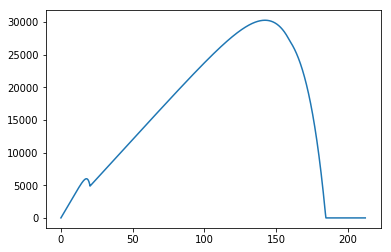

In [10]:
%run Graphs2.ipynb
import warnings
warnings.filterwarnings('ignore')
from scipy.signal import find_peaks

observation = env.reset()
# print(observation)

irradiances = list([1000.])
temperatures = list([25.])
# [a, 10, b, 10, c, 10]
sh = list([[1,10,9,10,9,10]])
max_steps = 30000
# min_action = -5.
# max_action = 5.

observation = env.setTempIrr(observation, temperatures[0], irradiances[0], sh[0])
# data = DATA(observation, temperatures[0], irradiances[0])
powerlst = []
voltagelst = []

for i in range(len(temperatures)):
    #observation =  env.reset()
    observation = env.reset()
    env.setTempIrr(observation, temperatures[i], irradiances[i], sh[i])
    
   
    for j in range(max_steps):
#         tf_observation = tf.expand_dims(tf.convert_to_tensor(observation), 0)    
        action = 0.01
#         action = policy(tf_observation, ou_noise)
#         action = np.clip(action,min_action,max_action)
#         print(action)

        observation, reward, done, info = env.step(action)
        powerlst.append(observation[1])
        voltagelst.append(observation[0])

    plt.plot(voltagelst, powerlst)

In [11]:
print(info)

{'Steps': 30000, 'Current': 0, 'Irradiance': 1000.0, 'Shading': [1, 10, 9, 10, 9, 10], 'Temperature': 25.0}
